<a href="https://colab.research.google.com/github/24f3004113/ML-kaggle/blob/main/24f3004113_notebook_t32025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

cinema_audience_forecasting_challenge_path = kagglehub.competition_download('Cinema_Audience_Forecasting_challenge')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/Cinema_Audience_Forecasting_challenge/movie_theater_id_relation/movie_theater_id_relation.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/date_info/date_info.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_theaters/booknow_theaters.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_booking/cinePOS_booking.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_theaters/cinePOS_theaters.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_visits/booknow_visits.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_booking/booknow_booking.csv


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


# Data loading

In [ ]:
import pandas as pd

booknow_booking = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_booking/booknow_booking.csv")
booknow_theaters = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_theaters/booknow_theaters.csv")
booknow_visits = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_visits/booknow_visits.csv")
cinePOS_booking = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_booking/cinePOS_booking.csv")
cinePOS_theaters = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_theaters/cinePOS_theaters.csv")
movie_theater_id_relation = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/movie_theater_id_relation/movie_theater_id_relation.csv")
date_info  = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/date_info/date_info.csv")
sample_submission = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv")

print("Data Loading is Completed")

Data Loading is Completed


# **Exploratory Data Analysis**


# Preview, Info, Statistical summary about each Datasets

### `booknow_booking` Dataset

In [ ]:
display(booknow_booking.shape) #Shape of the dataset
display(booknow_booking.head()) #preview of 1st 5 rows
display(booknow_booking.info()) #standard info about dataset
display(booknow_booking.describe().T) #basic statistical summary of numerical columns

(68336, 4)

,book_theater_id,show_datetime,booking_datetime,tickets_booked
0,book_00244,2023-01-01 19:00:00,2023-01-01 16:00:00,1
1,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,3
2,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,6
3,book_00244,2023-01-01 20:00:00,2023-01-01 16:00:00,2
4,book_00151,2023-01-01 20:00:00,2023-01-01 01:00:00,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68336 entries, 0 to 68335
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   book_theater_id   68336 non-null  object
 1   show_datetime     68336 non-null  object
 2   booking_datetime  68336 non-null  object
 3   tickets_booked    68336 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 2.1+ MB


None

,count,mean,std,min,25%,50%,75%,max
tickets_booked,68336.0,4.425808,4.808945,1.0,2.0,3.0,5.0,100.0


In [ ]:
display(booknow_booking['book_theater_id'].nunique()) #No. of unique theaters present in book_theater_id

301

* ### Shape of the `booknow_booking` Dataset is `(68336, 4)`.
* ### There no NaN values in any Columns.
* ### There are 4 Columns namely ***book_theater_id, 	show_datetime, 	booking_datetime, 	tickets_booked***.
* ###  ***book_theater_id*** is categorical variable and Object DataType.
* ###  ***show_datetime & booking_datetime*** are in Object DataType to be coverted DataTime DataType.
* ### There are only `301` unique theater ids present in ***book_theater_id*** column.

### `booknow_theaters` Dataset

In [ ]:
display(booknow_theaters.shape) #Shape of the dataset
display(booknow_theaters.head()) #preview of 1st 5 rows
display(booknow_theaters.info()) #standard info about dataset
display(booknow_theaters.describe().T) # basic statistical summary of numerical columns

(829, 5)

,book_theater_id,theater_type,theater_area,latitude,longitude
0,book_00093,Drama,Area_001,22.619233,78.113017
1,book_00078,Drama,Area_001,22.619233,78.113017
2,book_00291,Drama,Area_001,22.619233,78.113017
3,book_00258,Drama,Area_001,22.619233,78.113017
4,book_00212,Drama,Area_002,23.004410,79.934515


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   book_theater_id  314 non-null    object 
 1   theater_type     829 non-null    object 
 2   theater_area     829 non-null    object 
 3   latitude         829 non-null    float64
 4   longitude        829 non-null    float64
dtypes: float64(2), object(3)
memory usage: 32.5+ KB


None

,count,mean,std,min,25%,50%,75%,max
latitude,829.0,23.0,0.833863,22.025970,22.619233,23.004410,23.018784,26.349436
longitude,829.0,79.0,1.460388,76.112098,78.170501,79.908065,79.934515,81.743235


In [ ]:
#checking for null values present in the dataset
display(booknow_theaters.isnull().sum())

book_theater_id    515
theater_type         0
theater_area         0
latitude             0
longitude            0
dtype: int64

In [ ]:
#checkng for No. of unique values present in each column
display(booknow_theaters.nunique())

book_theater_id    314
theater_type         4
theater_area       103
latitude           108
longitude          108
dtype: int64

In [ ]:
# printing list of unique vaues present to find type of theaters present in theater_type column
print(booknow_theaters['theater_type'].unique())

['Drama' 'Other' 'Action' 'Comedy']


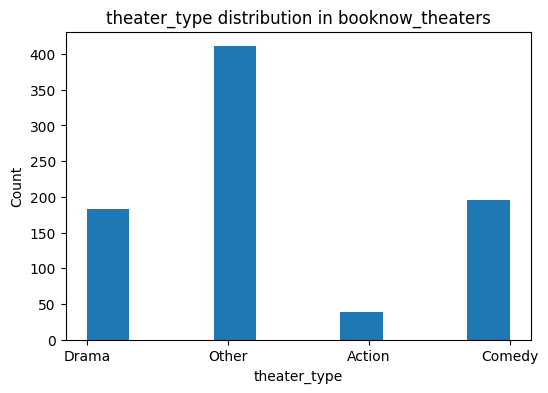

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.hist(booknow_theaters['theater_type'])
plt.xlabel("theater_type")
plt.ylabel("Count")
plt.title("theater_type distribution in booknow_theaters")
plt.show()

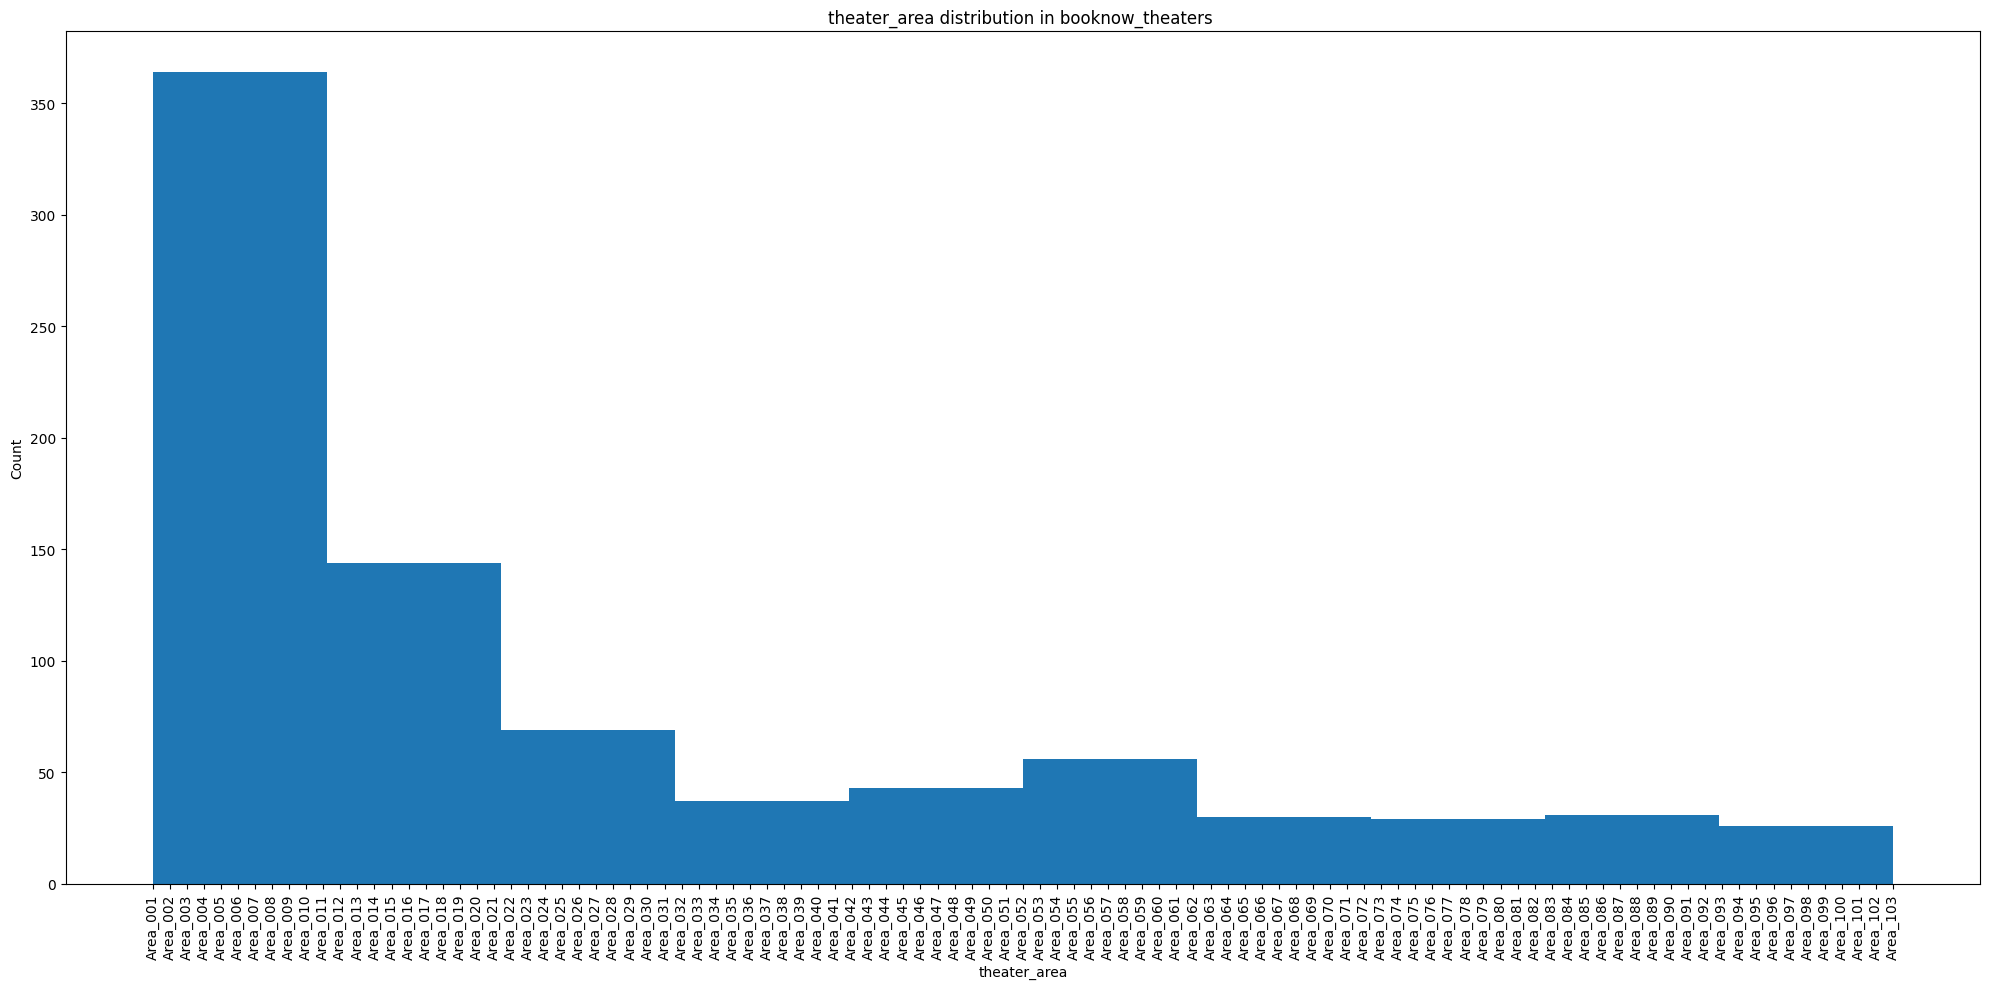

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
plt.hist(booknow_theaters['theater_area'])
plt.xlabel("theater_area")
plt.ylabel("Count")
plt.title("theater_area distribution in booknow_theaters ")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

* ### Shape of the `booknow_theaters` Dataset is `(829, 5)`.
* ### There `515` NaN values in ***book_theater_id*** Column.
* ### There are `5` Columns namely ***book_theater_id, 	theater_type, 	theater_area, 	latitude, 	longitude***.
* ###  ***book_theater_id, 	theater_type, 	theater_area*** are categorical variable and Object DataType.
* ### There are only `314` unique theater ids in ***book_theater_id*** column.
* ###  ***theater_type*** coulmn as `4` unique value having type of movies of particular theater *( i.e 'Drama', 'Other', 'Action', 'Comedy' )*.
* ### There are `103` different areas where ***theaters*** are divided into.

### `booknow_visits` Dataset

In [ ]:
display(booknow_visits.shape) # Shape of the dataset
display(booknow_visits.head())# preview of 1st 5 rows
display(booknow_visits.info())# standard info about dataset
display(booknow_visits.describe().T)# basic statistical summary of numerical columns


(214046, 3)

,book_theater_id,show_date,audience_count
0,book_00001,2023-01-13,50
1,book_00001,2023-01-14,64
2,book_00001,2023-01-15,58
3,book_00001,2023-01-16,44
4,book_00001,2023-01-18,12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214046 entries, 0 to 214045
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   book_theater_id  214046 non-null  object
 1   show_date        214046 non-null  object
 2   audience_count   214046 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 4.9+ MB


None

,count,mean,std,min,25%,50%,75%,max
audience_count,214046.0,41.616568,32.834918,2.0,18.0,34.0,58.0,1350.0


In [ ]:
# checking number of unique theaters present
display(booknow_visits['book_theater_id'].nunique())

826

* ### Shape of the `booknow_visits` Dataset is `(214046, 3)`.
* ### There no NaN values in any Columns.
* ### There are 3 Columns namely ***book_theater_id,	show_date, 	audience_count***.
* ###  ***book_theater_id*** is categorical variable and Object DataType.
* ###  ***show_date*** are in Object DataType to be coverted DataTime DataType.
* ### There are only `826` unique theater ids present in ***book_theater_id*** column.

### `cinePOS_booking` Dataset

In [ ]:
display(cinePOS_booking.shape)# Shape of the dataset
display(cinePOS_booking.head())# preview of 1st 5 rows
display(cinePOS_booking.info())# standard info about dataset
display(cinePOS_booking.describe().T)# basic statistical summary of numerical columns

(1641966, 4)

,cine_theater_id,show_datetime,booking_datetime,tickets_sold
0,cinePOS_00001,2023-01-01 11:00:00,2023-01-01 09:00:00,1
1,cinePOS_00002,2023-01-01 13:00:00,2023-01-01 06:00:00,3
2,cinePOS_00003,2023-01-01 16:00:00,2023-01-01 14:00:00,2
3,cinePOS_00004,2023-01-01 17:00:00,2023-01-01 11:00:00,5
4,cinePOS_00005,2023-01-01 17:00:00,2023-01-01 03:00:00,13


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1641966 entries, 0 to 1641965
Data columns (total 4 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   cine_theater_id   1641966 non-null  object
 1   show_datetime     1641966 non-null  object
 2   booking_datetime  1641966 non-null  object
 3   tickets_sold      1641966 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 50.1+ MB


None

,count,mean,std,min,25%,50%,75%,max
tickets_sold,1641966.0,4.987345,5.234901,1.0,2.0,3.0,6.0,100.0


In [ ]:
display(cinePOS_booking['cine_theater_id'].nunique())

13161

* ### Shape of the `cinePOS_booking` Dataset is `(1641966, 4)`.
* ### There no NaN values in any Columns.
* ### There are 4 Columns namely ***cine_theater_id, 	show_datetime, 	booking_datetime, 	tickets_sold***.
* ### ***cine_theater_id*** is categorical variable and Object DataType.
* ### ***show_datetime & booking_datetime*** are in Object DataType to be coverted DataTime DataType.
* ### There are only `13161` unique theater ids present in ***cine_theater_id*** column.

### `cinePOS_theaters` Dataset

In [ ]:
display(cinePOS_theaters.shape)
display(cinePOS_theaters.head())
display(cinePOS_theaters.info())
display(cinePOS_theaters.describe().T)

(4690, 5)

,cine_theater_id,theater_type,theater_area,latitude,longitude
0,cinePOS_05466,Other,Area_104,22.619233,78.113017
1,cinePOS_08708,Other,Area_104,22.619233,78.113017
2,cinePOS_00753,Other,Area_104,22.619233,78.113017
3,cinePOS_05776,Other,Area_104,22.619233,78.113017
4,cinePOS_07536,Other,Area_104,23.004410,79.934515


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4690 entries, 0 to 4689
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cine_theater_id  4690 non-null   object 
 1   theater_type     4690 non-null   object 
 2   theater_area     4690 non-null   object 
 3   latitude         829 non-null    float64
 4   longitude        829 non-null    float64
dtypes: float64(2), object(3)
memory usage: 183.3+ KB


None

,count,mean,std,min,25%,50%,75%,max
latitude,829.0,23.0,0.833863,22.025970,22.619233,23.004410,23.018784,26.349436
longitude,829.0,79.0,1.460388,76.112098,78.170501,79.908065,79.934515,81.743235


In [ ]:
#checking for null values present in the dataset
display(cinePOS_theaters.isnull().sum())

cine_theater_id       0
theater_type          0
theater_area          0
latitude           3861
longitude          3861
dtype: int64

In [ ]:
#checking for No. of unique values present in each column
display(cinePOS_theaters.nunique())

cine_theater_id    4690
theater_type          3
theater_area        119
latitude            108
longitude           108
dtype: int64

In [ ]:
# Printing List of theater types
print(cinePOS_theaters['theater_type'].unique())

['Other' 'Drama' 'Action']


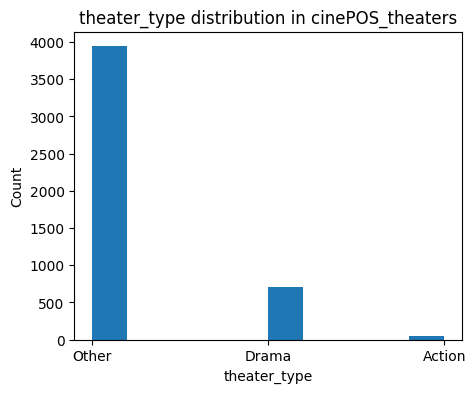

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))
plt.hist(cinePOS_theaters['theater_type'])
plt.xlabel("theater_type")
plt.ylabel("Count")
plt.title("theater_type distribution in cinePOS_theaters")
plt.show()

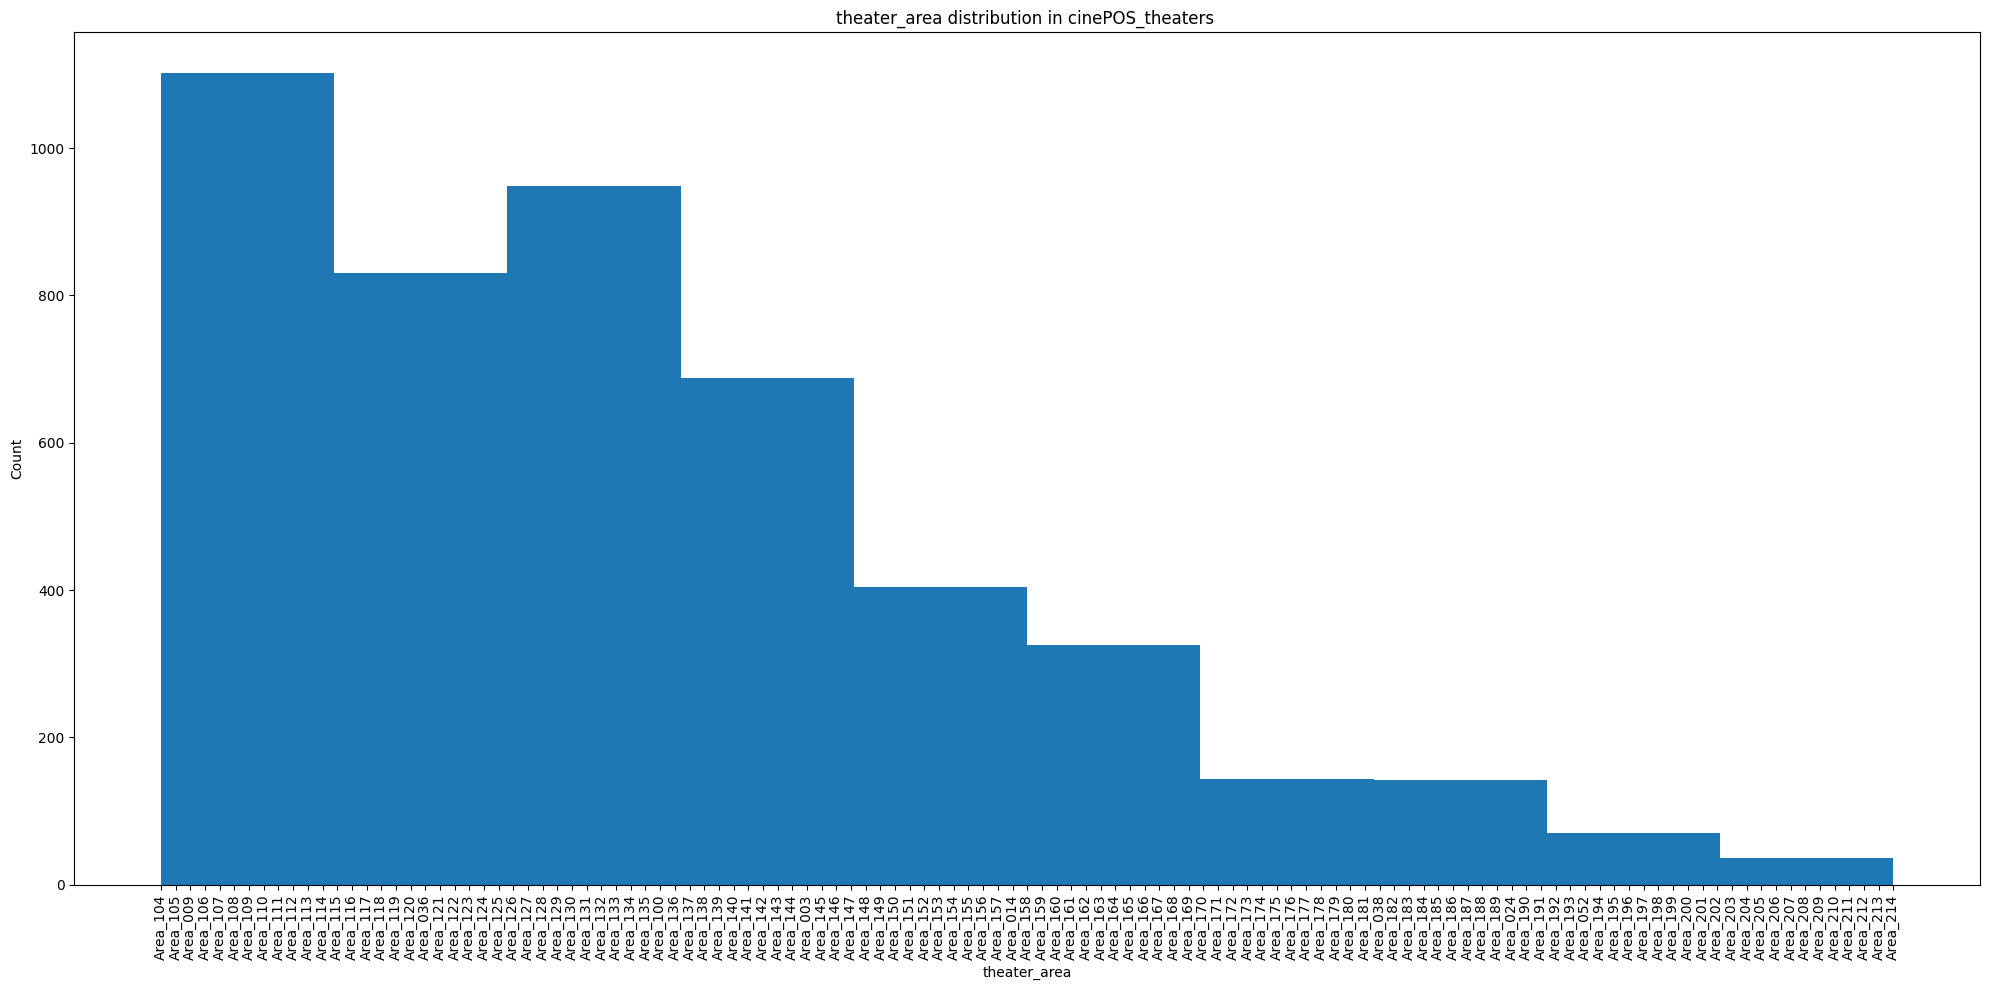

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
plt.hist(cinePOS_theaters['theater_area'])
plt.xlabel("theater_area")
plt.ylabel("Count")
plt.title("theater_area distribution in cinePOS_theaters ")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

* ### Shape of the `cinePOS_theaters` Dataset is `(829, 5)`.
* ### There are `3861` NaN values in ***latitude & longitude*** Columns.
* ### There are `5` Columns namely ***cine_theater_id, 	theater_type, 	theater_area, 	latitude, 	longitude***.
* ###  ***cine_theater_id, 	theater_type, 	theater_area*** are categorical variable and Object DataType.
* ### There are only `4690` unique theater ids in ***cine_theater_id*** column.
* ###  ***theater_type*** coulmn as `3` unique value having type of movies of particular theater *( i.e 'Drama', 'Other', 'Action' )*.
* ### There are `119` different areas where ***theaters*** are divided into.

### `movie_theater_id_relation` Dataset

In [ ]:
display(movie_theater_id_relation.shape) #Shape of the dataset
display(movie_theater_id_relation.head()) #Preview of 1st 5 rows
display(movie_theater_id_relation.info()) # Sytandard info the dataset

(150, 2)

,book_theater_id,cine_theater_id
0,book_00509,cinePOS_01261
1,book_00063,cinePOS_02467
2,book_00054,cinePOS_08923
3,book_00094,cinePOS_02479
4,book_00052,cinePOS_06750


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   book_theater_id  150 non-null    object
 1   cine_theater_id  150 non-null    object
dtypes: object(2)
memory usage: 2.5+ KB


None

* ### Shape of the `movie_theater_id_relation` Dataset is `(150, 2)`.

* ### There are `2` Columns namely ***book_theater_id, cine_theater_id***.
* ###  ***cine_theater_id, 	cine_theater_id*** are categorical variable and Object DataType.
* ### This dataset has a mapping data of `150` theater id from ***book_theater_id***  to  ***cine_theater_id***

### `sample_submission` Dataset

In [ ]:
display(sample_submission.head()) # Preview of Submission csv file

,ID,audience_count
0,book_00001_2024-03-01,0
1,book_00001_2024-03-02,0
2,book_00001_2024-03-03,0
3,book_00001_2024-03-04,0
4,book_00001_2024-03-06,0


### Spliting of ID column into ***book_theater_id*** , ***show_date*** columns

In [ ]:
theaters_for_sub = sample_submission.copy() # copying sample submission file to understanding the requirement

# spliting of ID column into book_theater_id , show_date columns
theaters_for_sub[['book_theater_id', 'show_date']] = theaters_for_sub ['ID'].str.rsplit('_', n=1, expand=True)

display(theaters_for_sub.head())

,ID,audience_count,book_theater_id,show_date
0,book_00001_2024-03-01,0,book_00001,2024-03-01
1,book_00001_2024-03-02,0,book_00001,2024-03-02
2,book_00001_2024-03-03,0,book_00001,2024-03-03
3,book_00001_2024-03-04,0,book_00001,2024-03-04
4,book_00001_2024-03-06,0,book_00001,2024-03-06


In [ ]:
theaters_for_sub['book_theater_id'].nunique()

827

* ### there are  `827` theaters data in `sample_submission`
* ### So it would be sufficient to have data about only required theater id in sample submission

In [ ]:
#Creating DataFrame of Unique Theater Ids present in sample submission dataset
theaters_from_sample= {
    'uniq_theaters_from_sample' : theaters_for_sub['book_theater_id'].unique()
}
theaters_from_sample_uniq=pd.DataFrame(theaters_from_sample)

### converting date columns from object dtype to DateTime dtype in `booknow_booking` Dataset

In [ ]:
# converting Object dtype to DateTime dtype
booknow_booking['show_datetime'] = pd.to_datetime(booknow_booking['show_datetime'])
booknow_booking['booking_datetime'] = pd.to_datetime(booknow_booking['booking_datetime'])

# extracting only Date from datetime
booknow_booking['show_date'] = booknow_booking['show_datetime'].dt.date

In [ ]:
# checking if the datatime conversion is done
display(booknow_booking.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68336 entries, 0 to 68335
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   book_theater_id   68336 non-null  object        
 1   show_datetime     68336 non-null  datetime64[ns]
 2   booking_datetime  68336 non-null  datetime64[ns]
 3   tickets_booked    68336 non-null  int64         
 4   show_date         68336 non-null  object        
dtypes: datetime64[ns](2), int64(1), object(2)
memory usage: 2.6+ MB


None

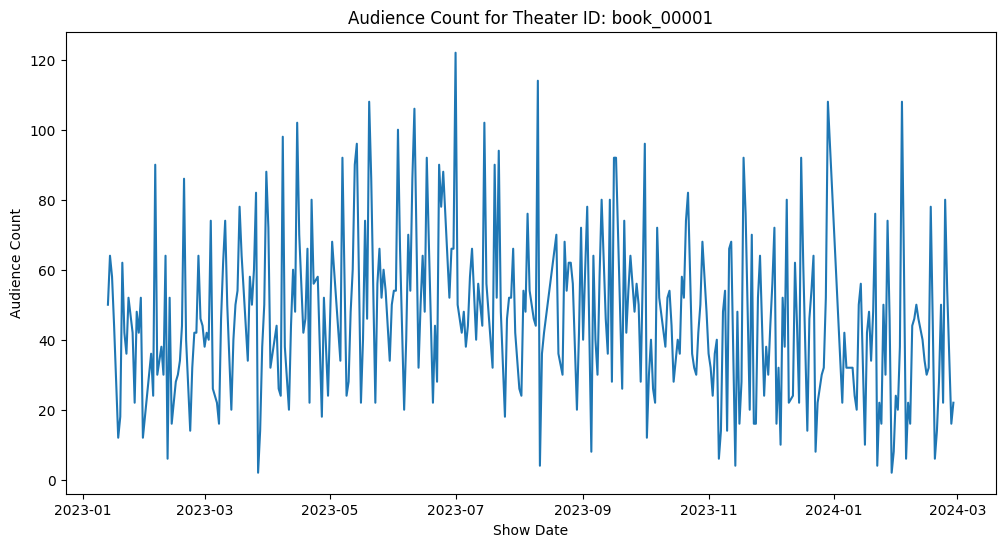

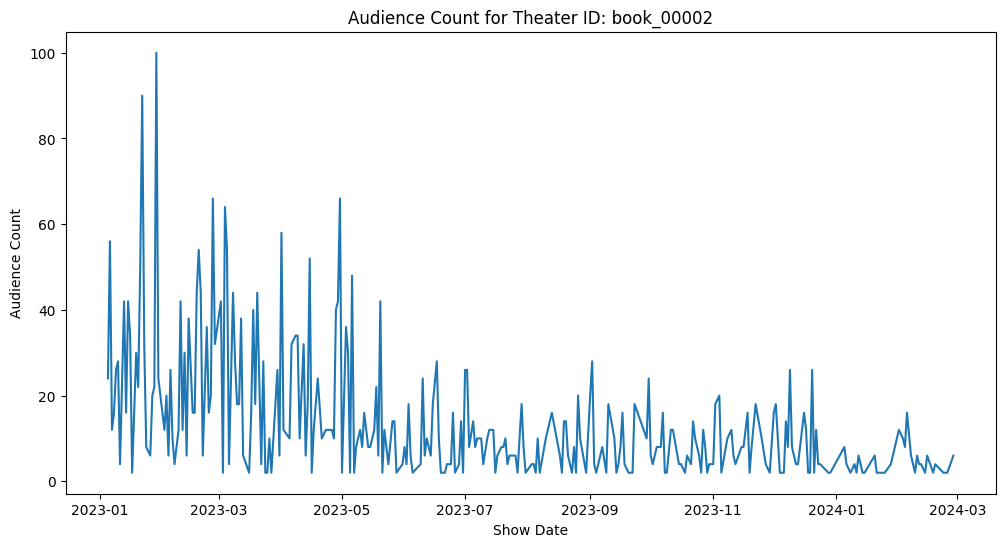

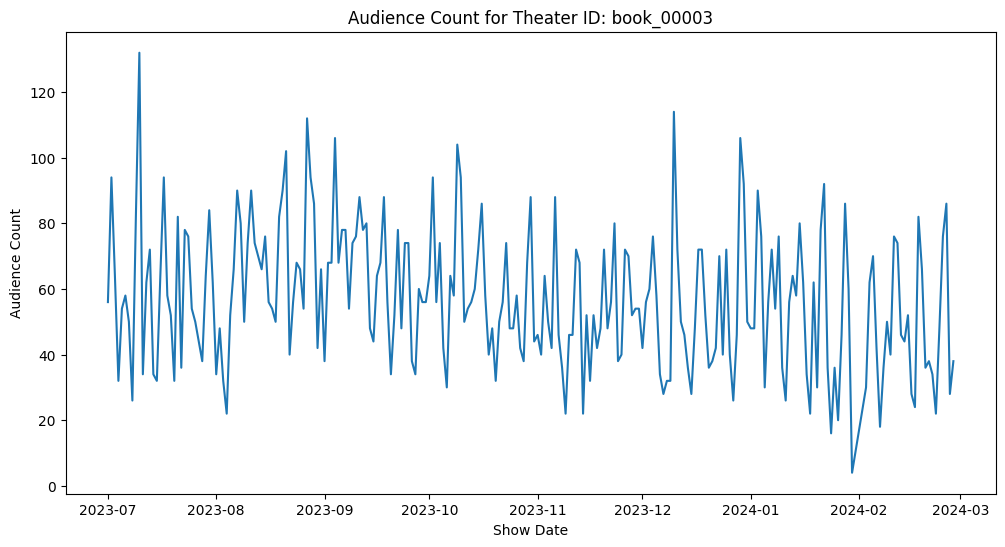

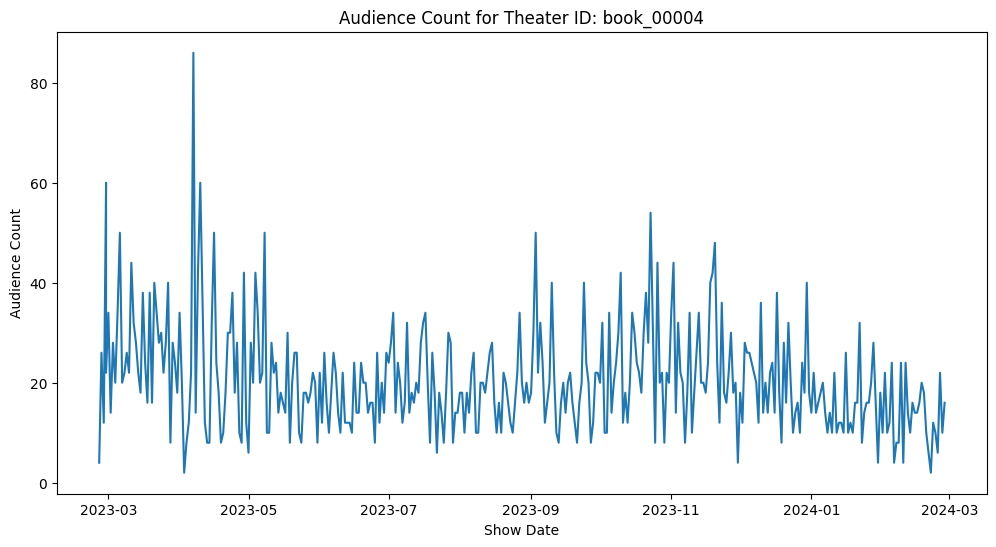

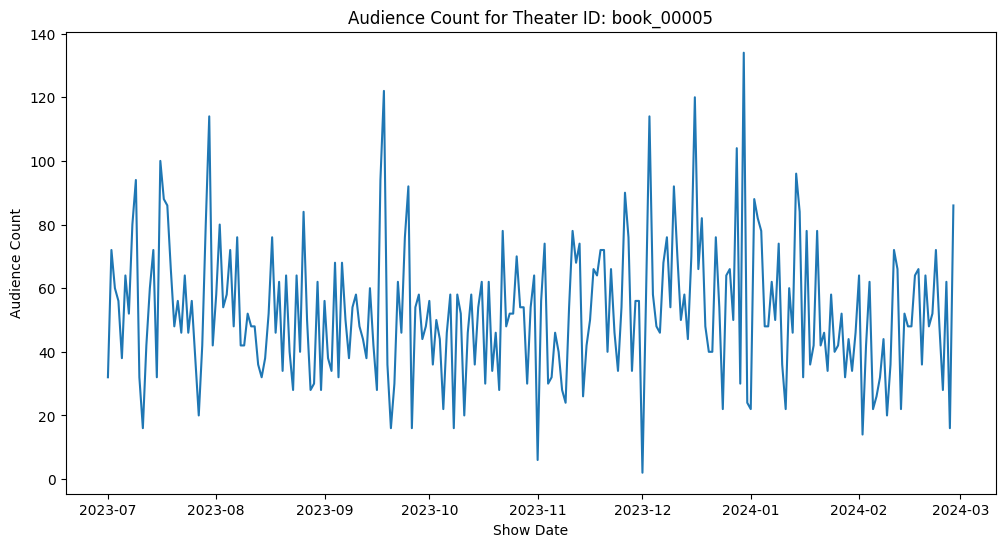

In [ ]:
import matplotlib.pyplot as plt

# converting Object dtype to DateTime dtype
booknow_visits['show_date'] = pd.to_datetime(booknow_visits['show_date'])

# selecting unique theaters form booknow visit data
uniq_visit_theater = booknow_visits['book_theater_id'].unique()

# Plotting for the first 5 unique theaters as an example
for theater_id in uniq_visit_theater[:5]:
    visit_theaters = booknow_visits[booknow_visits['book_theater_id'] == theater_id]

    plt.figure(figsize=(12, 6))
    plt.plot(visit_theaters['show_date'],visit_theaters['audience_count'])
    plt.title(f'Audience Count for Theater ID: {theater_id}')
    plt.xlabel('Show Date')
    plt.ylabel('Audience Count')
    plt.show()

In [ ]:
# convert show_date column to DateTime dtype as it extracted as object dtype
booknow_booking['show_date'] = pd.to_datetime(booknow_booking['show_date'])

#creating New DataFrame grouping theater id and show date by summing tickets booked for particular date in particular theater
dated_booknow_booking = booknow_booking.groupby(['book_theater_id', 'show_date'], as_index=False)['tickets_booked'].sum().reset_index(drop=True)

#renaming tickets booked column as total tickets booked in new DataFrame
dated_booknow_booking = dated_booknow_booking.rename(columns={'tickets_booked': 'total_tickets_booked'})

#sorting by theater id and reseting index
dated_booknow_booking = dated_booknow_booking.sort_values(by='book_theater_id').reset_index(drop=True)

display(dated_booknow_booking.shape) #shape of modified dataset
display(dated_booknow_booking.head()) #preview of modified dataset
display(dated_booknow_booking.info())

(21590, 3)

,book_theater_id,show_date,total_tickets_booked
0,book_00004,2023-02-27,12
1,book_00013,2023-12-18,13
2,book_00013,2023-12-17,12
3,book_00013,2023-12-12,3
4,book_00013,2023-12-11,27


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21590 entries, 0 to 21589
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   book_theater_id       21590 non-null  object        
 1   show_date             21590 non-null  datetime64[ns]
 2   total_tickets_booked  21590 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 506.1+ KB


None

### converting date columns from object dtype to DateTime dtype in `cinePOS_booking` Dataset

In [ ]:
# converting Object dtype to DateTime dtype
cinePOS_booking['show_datetime'] = pd.to_datetime(cinePOS_booking['show_datetime'])
cinePOS_booking['booking_datetime'] = pd.to_datetime(cinePOS_booking['booking_datetime'])

# extracting only Date from datetime
cinePOS_booking['show_date'] = cinePOS_booking['show_datetime'].dt.date

In [ ]:
# checking if the datatime conversion is done
display(cinePOS_booking.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1641966 entries, 0 to 1641965
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   cine_theater_id   1641966 non-null  object        
 1   show_datetime     1641966 non-null  datetime64[ns]
 2   booking_datetime  1641966 non-null  datetime64[ns]
 3   tickets_sold      1641966 non-null  int64         
 4   show_date         1641966 non-null  object        
dtypes: datetime64[ns](2), int64(1), object(2)
memory usage: 62.6+ MB


None

In [ ]:
# convert show_date column to DateTime dtype as it extracted as object dtype
cinePOS_booking['show_date'] = pd.to_datetime(cinePOS_booking['show_date'])

#creating New DataFrame grouping theater id and show date by summing tickets booked for particular date in particular theater
dated_cinePOS_booking = cinePOS_booking.groupby(['cine_theater_id', 'show_date'])['tickets_sold'].sum().reset_index()

#renaming tickets booked column as total tickets booked in new DataFrame
dated_cinePOS_booking = dated_cinePOS_booking.rename(columns={'tickets_sold': 'total_tickets_sold'})

#sorting by theater id and reseting index
dated_cinePOS_booking = dated_cinePOS_booking.sort_values(by=['cine_theater_id', 'show_date']).reset_index(drop=True)


display(dated_cinePOS_booking.shape) #shape of modified dataset
display(dated_cinePOS_booking.head()) #preview of modified dataset
display(dated_cinePOS_booking.info())

(1120081, 3)

,cine_theater_id,show_date,total_tickets_sold
0,cinePOS_00001,2023-01-01,1
1,cinePOS_00001,2023-01-08,1
2,cinePOS_00001,2023-01-23,5
3,cinePOS_00001,2023-01-24,5
4,cinePOS_00001,2023-01-28,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1120081 entries, 0 to 1120080
Data columns (total 3 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   cine_theater_id     1120081 non-null  object        
 1   show_date           1120081 non-null  datetime64[ns]
 2   total_tickets_sold  1120081 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 25.6+ MB


None

### converting date columns from object dtype to DateTime dtype in `booknow_visits` Dataset

In [ ]:
# converting Object dtype to DateTime dtype
booknow_visits['show_date'] = pd.to_datetime(booknow_visits['show_date'])

In [ ]:
# checking if the datatime conversion is done
display(booknow_visits.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214046 entries, 0 to 214045
Data columns (total 3 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   book_theater_id  214046 non-null  object        
 1   show_date        214046 non-null  datetime64[ns]
 2   audience_count   214046 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 4.9+ MB


None

In [ ]:
#collecting unique book_theater_id from booknow_visits
theaters_from_visits= {
    'uniq_theaters_from_visits' : booknow_visits['book_theater_id'].unique()
}

# creating data frame of unique theater in booknow visits data set
theaters_from_visits_uniq=pd.DataFrame(theaters_from_visits)



In [ ]:
# merging unique theater of booknow visit to unique theater in sample submission with

theater_visit_sample_merged= theaters_from_visits_uniq.merge(theaters_from_sample_uniq,
                   left_on = 'uniq_theaters_from_visits',
                   right_on = 'uniq_theaters_from_sample',
                   how='outer')

# to find book_theater_id present in book_visits  data but missing in sample_submission data or present in sample_submission data but missing in book_visits data
display(theater_visit_sample_merged.loc[
        (theater_visit_sample_merged['uniq_theaters_from_sample'].isnull())
        |
        (theater_visit_sample_merged['uniq_theaters_from_visits'].isnull())])



,uniq_theaters_from_visits,uniq_theaters_from_sample
39,NaN,book_00040
358,NaN,book_00359
490,book_00491,NaN
501,book_00502,NaN
525,NaN,book_00526


### `book_theater_ids (book_00491 ,book_00502)` are present in `booknow_visit` data but not present in `sample_submission`



 ### `book_theater_ids (book_00040,book_00359,book_00526)` are present in `sample_submission` but not present in `booknow_visits data`

In [ ]:
# checking for unique number of theatres in book now booking

len(booknow_booking['book_theater_id'].unique())

301

### there are only `301` theaters data in `booknow_booking`
### there are  `827` theaters data in `sample_submission`
### there are  `826` theaters data in `booknow_visits`

In [ ]:
# checking for book_00040,book_00359,book_00526 in booknow_booking

dated_booknow_booking.loc[dated_booknow_booking['book_theater_id'].isin(['book_00040','book_00359','book_00526']) ]

,book_theater_id,show_date,total_tickets_booked
1173,book_00040,2024-01-29,2
1174,book_00040,2024-01-21,4
1175,book_00040,2024-01-28,22
1176,book_00040,2024-01-27,3
1177,book_00040,2024-01-26,14
...,...,...,...
15017,book_00526,2024-02-22,61
15018,book_00526,2024-02-16,37
15019,book_00526,2024-02-15,15
15020,book_00526,2024-01-03,3


In [ ]:
#Merging cinePOS book Data and movies theater ID relation by outer merge
cinePOS_book_merge=dated_cinePOS_booking.merge(movie_theater_id_relation,
                   left_on = 'cine_theater_id',
                   right_on = 'cine_theater_id',
                   how='outer')

#converting object data type to datetime data type
cinePOS_book_merge['show_date']=pd.to_datetime(cinePOS_book_merge['show_date'])

# checking for book_00040,book_00359,book_00526 in cinePOS book Data
cinePOS_book_merge.loc[cinePOS_book_merge['book_theater_id'].isin(['book_00040','book_00359','book_00526']) ]



,cine_theater_id,show_date,total_tickets_sold,book_theater_id
740499,cinePOS_06615,2023-01-14,2,book_00526
740500,cinePOS_06615,2023-01-21,2,book_00526
740501,cinePOS_06615,2023-01-30,4,book_00526
740502,cinePOS_06615,2023-01-31,3,book_00526
740503,cinePOS_06615,2023-02-04,2,book_00526
...,...,...,...,...
1026436,cinePOS_11127,2024-02-21,5,book_00040
1026437,cinePOS_11127,2024-02-24,15,book_00040
1026438,cinePOS_11127,2024-02-25,7,book_00040
1026439,cinePOS_11127,2024-02-26,8,book_00040


In [ ]:

#converting object data type to datetime data type
dated_booknow_booking['show_date']=pd.to_datetime(dated_booknow_booking['show_date'])

##Merging cinePOS_book_merge Data and dated_booknow_booking by outer merge
cinePOS_booking_merge=cinePOS_book_merge.merge(dated_booknow_booking,
                   left_on = ['book_theater_id','show_date'],
                   right_on = ['book_theater_id','show_date'],
                   how='outer')

#converting object data type to datetime data type
cinePOS_booking_merge['show_date']=pd.to_datetime(cinePOS_booking_merge['show_date'])

# checking if there exist any relation between tickets sold or tickets booked to audience count
display(
    cinePOS_booking_merge.loc[
        (cinePOS_booking_merge['book_theater_id'] == 'book_00093') &
        (cinePOS_booking_merge['show_date'] == pd.to_datetime('2023-01-02'))
    ]
)

display(
    booknow_visits.loc[
        (booknow_visits['book_theater_id'] == 'book_00093') &
        (booknow_visits['show_date'] == pd.to_datetime('2023-01-02'))
    ]
)


,cine_theater_id,show_date,total_tickets_sold,book_theater_id,total_tickets_booked
7762,cinePOS_00237,2023-01-02,9.0,book_00093,11.0


,book_theater_id,show_date,audience_count
23249,book_00093,2023-01-02,192


### as we can see above `book_00093` is taken as example if there exists any sum up between tickets booked online is `11` and POS ticket is `9` but tickets booked offline and online add upto `20` but doesn't match with audience count on `2023-01-02` date

* ### lets add total_tickets_sold and total_tickets_booked to get some data for `['book_00040','book_00359','book_00526'] ` who auidence count is missing
* ### As missing theaters don't have any audience count data available in book now visit dataframe. I am considering to add up tickets sold and tickets book as audience count. this is being done because having some data having is best than having no data . some data can train the model to have predictions. Even though there is no connection between between tickets sold and tickets booked with audience count as checked with an example in book 00093 theater ID

In [ ]:
# preview available data of tickets sold and tickets booked for the missing theaters in booknow visit data
display(
    cinePOS_booking_merge.loc[
        (cinePOS_booking_merge['book_theater_id'].isin(['book_00040','book_00359','book_00526']) )
    ]
)

,cine_theater_id,show_date,total_tickets_sold,book_theater_id,total_tickets_booked
2048,cinePOS_11127,2023-05-28,2.0,book_00040,NaN
2049,cinePOS_11127,2023-06-02,2.0,book_00040,NaN
2050,cinePOS_11127,2023-06-03,4.0,book_00040,NaN
2051,cinePOS_11127,2023-06-04,11.0,book_00040,NaN
2052,cinePOS_11127,2023-06-05,22.0,book_00040,NaN
...,...,...,...,...,...
24310,cinePOS_06615,2024-02-18,4.0,book_00526,52.0
24311,NaN,2024-02-19,NaN,book_00526,37.0
24312,NaN,2024-02-22,NaN,book_00526,61.0
24313,NaN,2024-02-25,NaN,book_00526,78.0


In [ ]:
# creating separate datafrae for missing details so that I can merge them back to the book now visits data so that we have no missing theater for predictions
missing_theaters= cinePOS_booking_merge[
    cinePOS_booking_merge['book_theater_id'].isin(['book_00040', 'book_00359', 'book_00526'])
]

# dropping unnecessary columns
missing_theaters = missing_theaters.drop(columns=['cine_theater_id']).reset_index(drop=True)

# filling null values with zero
missing_theaters = missing_theaters.fillna(0)

# adding total tickets sold and total tickets booked as audience count
missing_theaters['audience_count'] = missing_theaters['total_tickets_sold'] + missing_theaters['total_tickets_booked']

# dropping total ticket sold and total ticket booked and resetting the index
missing_theaters = missing_theaters.drop(columns=['total_tickets_sold','total_tickets_booked']).reset_index(drop=True)

# bringing book theater ID column to first column
missing_theaters = missing_theaters[['book_theater_id'] + [col for col in missing_theaters.columns if col != 'book_theater_id']]

missing_theaters

,book_theater_id,show_date,audience_count
0,book_00040,2023-05-28,2.0
1,book_00040,2023-06-02,2.0
2,book_00040,2023-06-03,4.0
3,book_00040,2023-06-04,11.0
4,book_00040,2023-06-05,22.0
...,...,...,...
273,book_00526,2024-02-18,56.0
274,book_00526,2024-02-19,37.0
275,book_00526,2024-02-22,61.0
276,book_00526,2024-02-25,78.0


In [ ]:
# adding up missing dates ID values to book now visits to make it full booknow visit data for predicting sample submission data
full_booknow_visits = pd.concat([booknow_visits,missing_theaters], ignore_index=True)

# Sorting book data ID and showDate and resetting index
full_booknow_visits = full_booknow_visits.sort_values(by=['book_theater_id', 'show_date']).reset_index(drop=True)

In [ ]:
#Number of a unique Theatre ID are present in full book now visits data this includes Two theatres which are not present in the sample submission data
full_booknow_visits['book_theater_id'].nunique()

829

In [ ]:
#Checking again for any missing theatres In comparison to sample submission Theatres requirement
full_theaters_from_visits= {
    'uniq_theaters_from_visits' : full_booknow_visits['book_theater_id'].unique()
}
full_theaters_from_visits_uniq=pd.DataFrame(full_theaters_from_visits)

full_theater_sample_visit_merge= theaters_from_sample_uniq.merge(full_theaters_from_visits_uniq,
                   left_on = 'uniq_theaters_from_sample',
                   right_on = 'uniq_theaters_from_visits',
                   how='left')

full_theater_sample_visit_merge.isnull().sum()

uniq_theaters_from_sample    0
uniq_theaters_from_visits    0
dtype: int64

### We can observe here that there is no missing theatre ids in comparison to sample submission data

### trying to add  features as  `theater_type` `theater_area` `latitude` `longitude`

In [ ]:
#Checking number of theaters which has features  theater_type theater_area latitude longitude
combined_theaters_with_features = pd.concat([
    booknow_theaters['book_theater_id'],
    movie_theater_id_relation['book_theater_id']
], ignore_index=True)
combined_theaters_with_features.nunique()

380

* ###   there are `827` unique theater ids in sample submission but we have only about `380` theaters ids with features like `theater_type` `theater_area` `latitude` `longitude`  among them there exists NaN values as well
* ###  there would no much of use to train a model with features listed above where about `827` - `380` = `447` theaters don't have feature values


In [ ]:
# copying sample submission dataTo include it as test data set in main training data set
forecast_df = sample_submission.copy()

#Splitting ID column into book theater ID and show date columns
forecast_df[['book_theater_id', 'show_date']] = forecast_df['ID'].str.rsplit('_', n=1, expand=True)

#droping ID and audience count columns
forecast_df.drop(columns=['ID', 'audience_count'], inplace=True)
forecast_df

,book_theater_id,show_date
0,book_00001,2024-03-01
1,book_00001,2024-03-02
2,book_00001,2024-03-03
3,book_00001,2024-03-04
4,book_00001,2024-03-06
...,...,...
38057,book_00829,2024-04-18
38058,book_00829,2024-04-19
38059,book_00829,2024-04-20
38060,book_00829,2024-04-21


# Feature Extraction

### finding features from `show_date` column of `full_booknow_visits` Data set

In [ ]:
full_booknow_visits['show_date'] = pd.to_datetime(full_booknow_visits['show_date']) #Converting object data type to datetime data type
full_booknow_visits['day'] = full_booknow_visits['show_date'].dt.day # Extracting day  of the month from show date
full_booknow_visits['month'] = full_booknow_visits['show_date'].dt.month #Extracting month of the year from show date
full_booknow_visits['year'] = full_booknow_visits['show_date'].dt.year # extracting year from show date
full_booknow_visits['dayofweek'] = full_booknow_visits['show_date'].dt.dayofweek # extracting day of the week from show date
full_booknow_visits['quarter'] = full_booknow_visits['show_date'].dt.quarter # extracting quarter of the year from show date
full_booknow_visits['is_weekend'] = (full_booknow_visits['dayofweek'] >= 5).astype(int) # creating features based on is a day in weekend i.e.Saturday and Sunday as 1, Monday to Friday as 0
full_booknow_visits['week_of_year'] = full_booknow_visits['show_date'].dt.isocalendar().week.astype(int) #Extracting week of the year from show date

full_booknow_visits

,book_theater_id,show_date,audience_count,day,month,year,dayofweek,quarter,is_weekend,week_of_year
0,book_00001,2023-01-13,50.0,13,1,2023,4,1,0,2
1,book_00001,2023-01-14,64.0,14,1,2023,5,1,1,2
2,book_00001,2023-01-15,58.0,15,1,2023,6,1,1,2
3,book_00001,2023-01-16,44.0,16,1,2023,0,1,0,3
4,book_00001,2023-01-18,12.0,18,1,2023,2,1,0,3
...,...,...,...,...,...,...,...,...,...,...
214319,book_00829,2024-02-23,16.0,23,2,2024,4,1,0,8
214320,book_00829,2024-02-24,8.0,24,2,2024,5,1,1,8
214321,book_00829,2024-02-25,16.0,25,2,2024,6,1,1,8
214322,book_00829,2024-02-27,16.0,27,2,2024,1,1,0,9


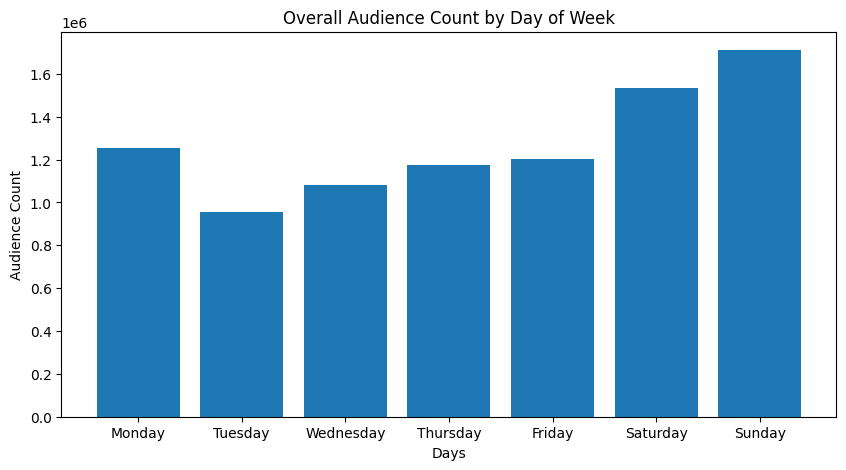

In [ ]:

overall_daily_audience = (full_booknow_visits.groupby('dayofweek')['audience_count'].sum())

plt.figure(figsize=(10, 5))
plt.bar(overall_daily_audience.index, overall_daily_audience.values)
plt.title("Overall Audience Count by Day of Week")
plt.xlabel("Days")
plt.ylabel("Audience Count")
plt.xticks(
    ticks=range(0, 7),
    labels=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.show()


### from the above plot it can be concluded that weekends (i.e saturday,sunday) has more audience then weekdays

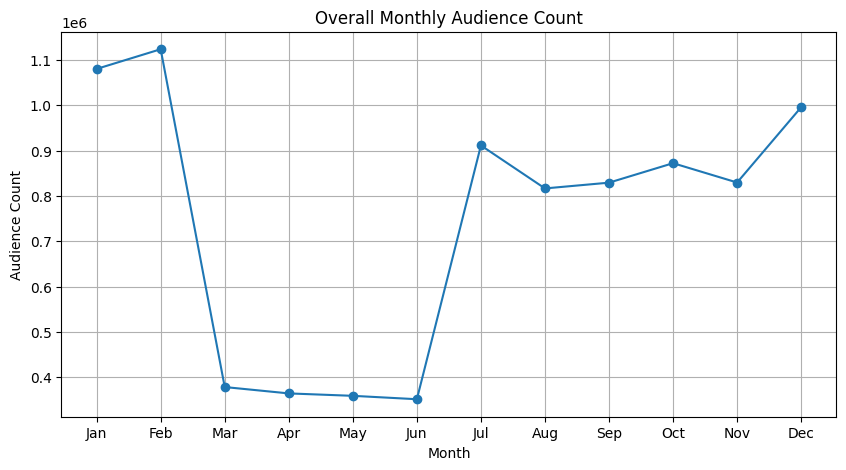

In [ ]:
overall_monthly_audience = (full_booknow_visits.groupby('month')['audience_count'].sum())

plt.figure(figsize=(10, 5))
plt.plot(overall_monthly_audience.index, overall_monthly_audience.values, marker='o')
plt.title("Overall Monthly Audience Count")
plt.xlabel("Month")
plt.ylabel("Audience Count")
plt.xticks(
    ticks=range(1, 13),
    labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
)
plt.grid(True)
plt.show()


### from the above plot it can be concluded that March to June shows least number audiences

### applying same features using `show_date` column of `forecast_df` Data set

In [ ]:
forecast_df['show_date'] = pd.to_datetime(forecast_df['show_date']) #Converting object data type to datetime data type
forecast_df['day'] = forecast_df['show_date'].dt.day # Extracting day  of the month from show date
forecast_df['month'] = forecast_df['show_date'].dt.month #Extracting month of the year from show date
forecast_df['year'] = forecast_df['show_date'].dt.year # extracting year from show date
forecast_df['dayofweek'] = forecast_df['show_date'].dt.dayofweek # extracting day of the week from show date
forecast_df['quarter'] = forecast_df['show_date'].dt.quarter # extracting quarter of the year from show date
forecast_df['is_weekend'] = (forecast_df['dayofweek'] >= 5).astype(int) # creating features based on is a day in weekend i.e.Saturday and Sunday as 1, Monday to Friday as 0
forecast_df['week_of_year'] = forecast_df['show_date'].dt.isocalendar().week.astype(int) #Extracting week of the year from show date

forecast_df

,book_theater_id,show_date,day,month,year,dayofweek,quarter,is_weekend,week_of_year
0,book_00001,2024-03-01,1,3,2024,4,1,0,9
1,book_00001,2024-03-02,2,3,2024,5,1,1,9
2,book_00001,2024-03-03,3,3,2024,6,1,1,9
3,book_00001,2024-03-04,4,3,2024,0,1,0,10
4,book_00001,2024-03-06,6,3,2024,2,1,0,10
...,...,...,...,...,...,...,...,...,...
38057,book_00829,2024-04-18,18,4,2024,3,2,0,16
38058,book_00829,2024-04-19,19,4,2024,4,2,0,16
38059,book_00829,2024-04-20,20,4,2024,5,2,1,16
38060,book_00829,2024-04-21,21,4,2024,6,2,1,16


In [ ]:
# labelling to separately identify training data as 0 and data to be forecasted as 1
full_booknow_visits['to_forecast']=0
forecast_df['to_forecast']=1

In [ ]:

# adding Training data and forecasting data into one to perform same feature enginerring
data_for_model = pd.concat([full_booknow_visits, forecast_df], ignore_index=True)
data_for_model

,book_theater_id,show_date,audience_count,day,month,year,dayofweek,quarter,is_weekend,week_of_year,to_forecast
0,book_00001,2023-01-13,50.0,13,1,2023,4,1,0,2,0
1,book_00001,2023-01-14,64.0,14,1,2023,5,1,1,2,0
2,book_00001,2023-01-15,58.0,15,1,2023,6,1,1,2,0
3,book_00001,2023-01-16,44.0,16,1,2023,0,1,0,3,0
4,book_00001,2023-01-18,12.0,18,1,2023,2,1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...
252381,book_00829,2024-04-18,NaN,18,4,2024,3,2,0,16,1
252382,book_00829,2024-04-19,NaN,19,4,2024,4,2,0,16,1
252383,book_00829,2024-04-20,NaN,20,4,2024,5,2,1,16,1
252384,book_00829,2024-04-21,NaN,21,4,2024,6,2,1,16,1


In [ ]:
# extracting statistical metrics like mean and standard deviation from auidence count column for each theater id
stats = data_for_model[data_for_model['to_forecast']==0].groupby("book_theater_id")['audience_count'].agg(['mean','std'])
stats.columns = ['theater_mean', 'theater_std']

# Adding addition feature as mean and standard deviation in audience count of each theater id
data_for_model = data_for_model.merge(stats, on='book_theater_id', how='left')

# filling mean values to forcast data where audience counts is to be forecasted and have null(NaN) values for now
data_for_model['theater_mean'] = data_for_model['theater_mean'].fillna(data_for_model['theater_mean'].mean())

# filling standard deviation values as 0 to forcast data where audience counts is to be forecasted and have null(NaN) values for now
data_for_model['theater_std']=data_for_model['theater_std'].fillna(0)


data_for_model

,book_theater_id,show_date,audience_count,day,month,year,dayofweek,quarter,is_weekend,week_of_year,to_forecast,theater_mean,theater_std
0,book_00001,2023-01-13,50.0,13,1,2023,4,1,0,2,0,47.058480,23.388397
1,book_00001,2023-01-14,64.0,14,1,2023,5,1,1,2,0,47.058480,23.388397
2,book_00001,2023-01-15,58.0,15,1,2023,6,1,1,2,0,47.058480,23.388397
3,book_00001,2023-01-16,44.0,16,1,2023,0,1,0,3,0,47.058480,23.388397
4,book_00001,2023-01-18,12.0,18,1,2023,2,1,0,3,0,47.058480,23.388397
...,...,...,...,...,...,...,...,...,...,...,...,...,...
252381,book_00829,2024-04-18,NaN,18,4,2024,3,2,0,16,1,11.147368,5.213877
252382,book_00829,2024-04-19,NaN,19,4,2024,4,2,0,16,1,11.147368,5.213877
252383,book_00829,2024-04-20,NaN,20,4,2024,5,2,1,16,1,11.147368,5.213877
252384,book_00829,2024-04-21,NaN,21,4,2024,6,2,1,16,1,11.147368,5.213877


# Preprocessing

In [ ]:
#importing neccesary tools for preprocessing
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

#Using OrdinalEncoder for tranforming categorical data into numerical encoding
OrdinalEncoder = OrdinalEncoder()
data_for_model['theater_enc'] = OrdinalEncoder.fit_transform(data_for_model[['book_theater_id']])

#using StandardScaler to normalise mean and std columns
StandardScaler = StandardScaler()
data_for_model[['theater_mean','theater_std']] = StandardScaler.fit_transform(
    data_for_model[['theater_mean','theater_std']]
)

data_for_model # view of tranformed data

,book_theater_id,show_date,audience_count,day,month,year,dayofweek,quarter,is_weekend,week_of_year,to_forecast,theater_mean,theater_std,theater_enc
0,book_00001,2023-01-13,50.0,13,1,2023,4,1,0,2,0,0.258050,0.063180,0.0
1,book_00001,2023-01-14,64.0,14,1,2023,5,1,1,2,0,0.258050,0.063180,0.0
2,book_00001,2023-01-15,58.0,15,1,2023,6,1,1,2,0,0.258050,0.063180,0.0
3,book_00001,2023-01-16,44.0,16,1,2023,0,1,0,3,0,0.258050,0.063180,0.0
4,book_00001,2023-01-18,12.0,18,1,2023,2,1,0,3,0,0.258050,0.063180,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
252381,book_00829,2024-04-18,NaN,18,4,2024,3,2,0,16,1,-1.443776,-1.315012,828.0
252382,book_00829,2024-04-19,NaN,19,4,2024,4,2,0,16,1,-1.443776,-1.315012,828.0
252383,book_00829,2024-04-20,NaN,20,4,2024,5,2,1,16,1,-1.443776,-1.315012,828.0
252384,book_00829,2024-04-21,NaN,21,4,2024,6,2,1,16,1,-1.443776,-1.315012,828.0


# Train and Test Split

In [ ]:
#selectng requried features for training and forecasting
features = ['day','month','year','dayofweek','is_weekend','week_of_year','theater_enc','theater_mean','theater_std']

# separating training data from full data using label added earlier
train_data = data_for_model[data_for_model['to_forecast']==0]

# separating training data from full data using label added earlier
test_forecast  = data_for_model[data_for_model['to_forecast']== 1]

# separating feature columns for training
X = train_data[features]

# taking auidence count column as target
y = train_data['audience_count']

# taking forcasting data as test data to forecast based pn training of train data
X_test = test_forecast[features]

#printing shapes of each separated data sets

print('X shape',X.shape )
print('y shape',y.shape )
print('X_test shape',X_test.shape )

X shape (214324, 9)
y shape (214324,)
X_test shape (38062, 9)


# Train Validate Split

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Implementing time series split as it is time series data
Time_Series_cv = TimeSeriesSplit(n_splits=5)

# Printing training index and validating index of split done by time series split
for train_index, validate_index in Time_Series_cv.split(X):
    print(train_index, validate_index)

[    0     1     2 ... 35721 35722 35723] [35724 35725 35726 ... 71441 71442 71443]
[    0     1     2 ... 71441 71442 71443] [ 71444  71445  71446 ... 107161 107162 107163]
[     0      1      2 ... 107161 107162 107163] [107164 107165 107166 ... 142881 142882 142883]
[     0      1      2 ... 142881 142882 142883] [142884 142885 142886 ... 178601 178602 178603]
[     0      1      2 ... 178601 178602 178603] [178604 178605 178606 ... 214321 214322 214323]


# **Model building**

# 1️⃣XGBoost Regressor

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(n_estimators=100, random_state=42)

xgb_rmse_scores = []
xgb_mae_scores = []
xgb_r2_scores = []
for train_index, validate_index in Time_Series_cv.split(X):
    X_train, X_validate = X.iloc[train_index], X.iloc[validate_index]
    y_train, y_validate = y.iloc[train_index], y.iloc[validate_index]

    xgb_model.fit(X_train, y_train)
    preds = np.maximum(xgb_model.predict(X_validate), 0)

    xgb_rmse_scores.append(mean_squared_error(y_validate, preds, squared=False))
    xgb_mae_scores.append(mean_absolute_error(y_validate, preds))
    xgb_r2_scores.append(r2_score(y_validate, preds))

print("XGBoost RMSE Scores:", xgb_rmse_scores)
print("XGBoost MAE Scores:",xgb_mae_scores)
print('XGBoost R2 Scores',xgb_r2_scores)


XGBoost RMSE Scores: [30.001427110627386, 26.899194276804856, 27.76947928739103, 29.93047715979328, 22.420541187234377]
XGBoost MAE Scores: [19.687301536923542, 17.13982396783841, 18.153663611241168, 17.281488686986478, 15.186868492322834]
XGBoost R2 Scores [0.20073134500081946, 0.28025610340752705, 0.28669284251707516, 0.18933652022351954, 0.4504921810912006]


# 2️⃣Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_rmse_scores = []
rf_mae_scores = []
rf_r2_scores = []
for train_index, validate_index in Time_Series_cv.split(X):
    X_train, X_validate = X.iloc[train_index], X.iloc[validate_index]
    y_train, y_validate = y.iloc[train_index], y.iloc[validate_index]

    rf_model.fit(X_train, y_train)
    preds = np.maximum(rf_model.predict(X_validate), 0)

    rf_rmse_scores.append(mean_squared_error(y_validate, preds, squared=False))
    rf_mae_scores.append(mean_absolute_error(y_validate, preds))
    rf_r2_scores.append(r2_score(y_validate, preds))

print("Random  Forest RMSE Scores:",rf_rmse_scores)
print("Random  Forest MAE Scores:",rf_mae_scores)
print('Random  Forest R2 Scores',rf_r2_scores)



Random  Forest RMSE Scores: [27.608473673385657, 25.871601733104978, 26.646790502259964, 26.073525411106523, 22.93167489556274]
Random  Forest MAE Scores: [18.30111868301072, 15.975945427398283, 17.595328568762334, 16.56605107982723, 15.679643756332322]
Random  Forest R2 Scores [0.3231479495434958, 0.3341964878182825, 0.34320335703385696, 0.3848049391646068, 0.42515170736047225]


# 3️⃣Light GBM Regressor

In [ ]:
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(n_estimators=100, random_state=42,verbose=-1)

lgb_rmse_scores = []
lgb_mae_scores = []
lgb_r2_scores = []
for train_index, validate_index in Time_Series_cv.split(X):
    X_train, X_validate = X.iloc[train_index], X.iloc[validate_index]
    y_train, y_validate = y.iloc[train_index], y.iloc[validate_index]

    lgb_model.fit(X_train, y_train)
    preds = np.maximum(lgb_model.predict(X_validate), 0)

    lgb_rmse_scores.append(mean_squared_error(y_validate, preds, squared=False))
    lgb_mae_scores.append(mean_absolute_error(y_validate, preds))
    lgb_r2_scores.append(r2_score(y_validate, preds))

print("LGBMRegressor RMSE Scores:",lgb_rmse_scores)
print("LGBMRegressor MAE Scores:",lgb_mae_scores)
print('LGBMRegressor R2 Scores',lgb_r2_scores)



LGBMRegressor RMSE Scores: [25.832462573960264, 24.844872194040473, 24.572669967470013, 24.149138959012767, 21.454286228486527]
LGBMRegressor MAE Scores: [17.116387697270323, 15.431723326129454, 15.981565015812857, 15.243003242666362, 14.676432261661004]
LGBMRegressor R2 Scores [0.407428756991299, 0.38599348175377757, 0.44147090061109173, 0.47226411229893983, 0.49683568327974126]


# 4️⃣GradientBoostingRegressor

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42
)

gbr_rmse_scores = []
gbr_mae_scores = []
gbr_r2_scores = []
for train_index, validate_index in Time_Series_cv.split(X):
    X_train, X_validate = X.iloc[train_index], X.iloc[validate_index]
    y_train, y_validate = y.iloc[train_index], y.iloc[validate_index]

    gbr_model.fit(X_train, y_train)
    preds = np.maximum(gbr_model.predict(X_validate), 0)

    gbr_rmse_scores.append(mean_squared_error(y_validate, preds, squared=False))
    gbr_mae_scores.append(mean_absolute_error(y_validate, preds))
    gbr_r2_scores.append(r2_score(y_validate, preds))

print("GradientBoostingRegressor RMSE Scores:",gbr_rmse_scores)
print("GradientBoostingRegressor MAE Scores:",gbr_mae_scores)
print('GradientBoostingRegressor R2 Scores',gbr_r2_scores)



GradientBoostingRegressor RMSE Scores: [25.644005369692735, 24.978482144233716, 24.54773865261491, 24.204942993139127, 21.3686900364067]
GradientBoostingRegressor MAE Scores: [17.005843866634432, 15.515793272160455, 16.01163559362823, 15.468222506679812, 14.607395393863419]
GradientBoostingRegressor R2 Scores [0.41604326419057425, 0.37937175565559933, 0.44260368763016544, 0.4698223011892039, 0.5008426246362244]


# 5️⃣HistGradientBoostingRegressor

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgbr_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_depth=5,
    max_iter=300,
    min_samples_leaf=20,
    l2_regularization=0.1,
    random_state=42
)



hgbr_rmse_scores = []
hgbr_mae_scores = []
hgbr_r2_scores = []
for train_index, validate_index in Time_Series_cv.split(X):
    X_train, X_validate = X.iloc[train_index], X.iloc[validate_index]
    y_train, y_validate = y.iloc[train_index], y.iloc[validate_index]

    hgbr_model.fit(X_train, y_train)
    preds = np.maximum(hgbr_model.predict(X_validate), 0)

    hgbr_rmse_scores.append(mean_squared_error(y_validate, preds, squared=False))
    hgbr_mae_scores.append(mean_absolute_error(y_validate, preds))
    hgbr_r2_scores.append(r2_score(y_validate, preds))
print("HistGradientBoostingRegressor RMSE Scores:",hgbr_rmse_scores)
print("HistGradientBoostingRegressor MAE Scores:",hgbr_mae_scores)
print('HistGradientBoostingRegressor R2 Scores',hgbr_r2_scores)



HistGradientBoostingRegressor RMSE Scores: [25.94131728949556, 24.788492979365106, 24.858628071122318, 24.733487394176198, 21.485329927970007]
HistGradientBoostingRegressor MAE Scores: [17.37400572138743, 15.09238008901446, 16.234990970814824, 15.796942204055533, 14.651118954016768]
HistGradientBoostingRegressor R2 Scores [0.40242419499071136, 0.3887769879433608, 0.42839578515021437, 0.44641535050325587, 0.495378502876328]


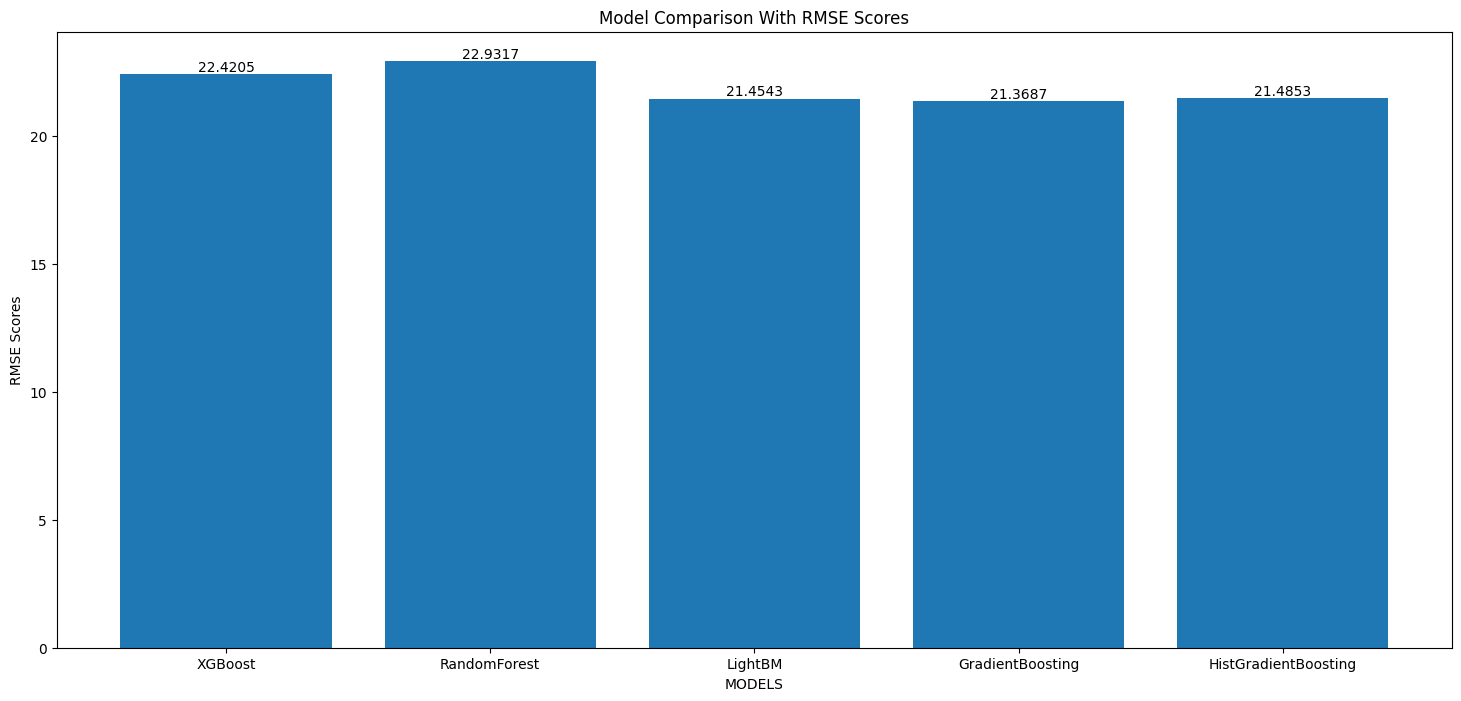

In [ ]:
import matplotlib.pyplot as plt


mins = [min(xgb_rmse_scores), min(rf_rmse_scores), min(lgb_rmse_scores), min(gbr_rmse_scores),min(hgbr_rmse_scores)]
labels = ['XGBoost', 'RandomForest', 'LightBM', 'GradientBoosting','HistGradientBoosting']

# Bar plot
plt.figure(figsize=(18,8))
bars =plt.bar(labels, mins)
plt.bar_label(bars, fmt="%.4f")
plt.title("Model Comparison With RMSE Scores")
plt.xlabel("MODELS")
plt.ylabel("RMSE Scores")
plt.show()


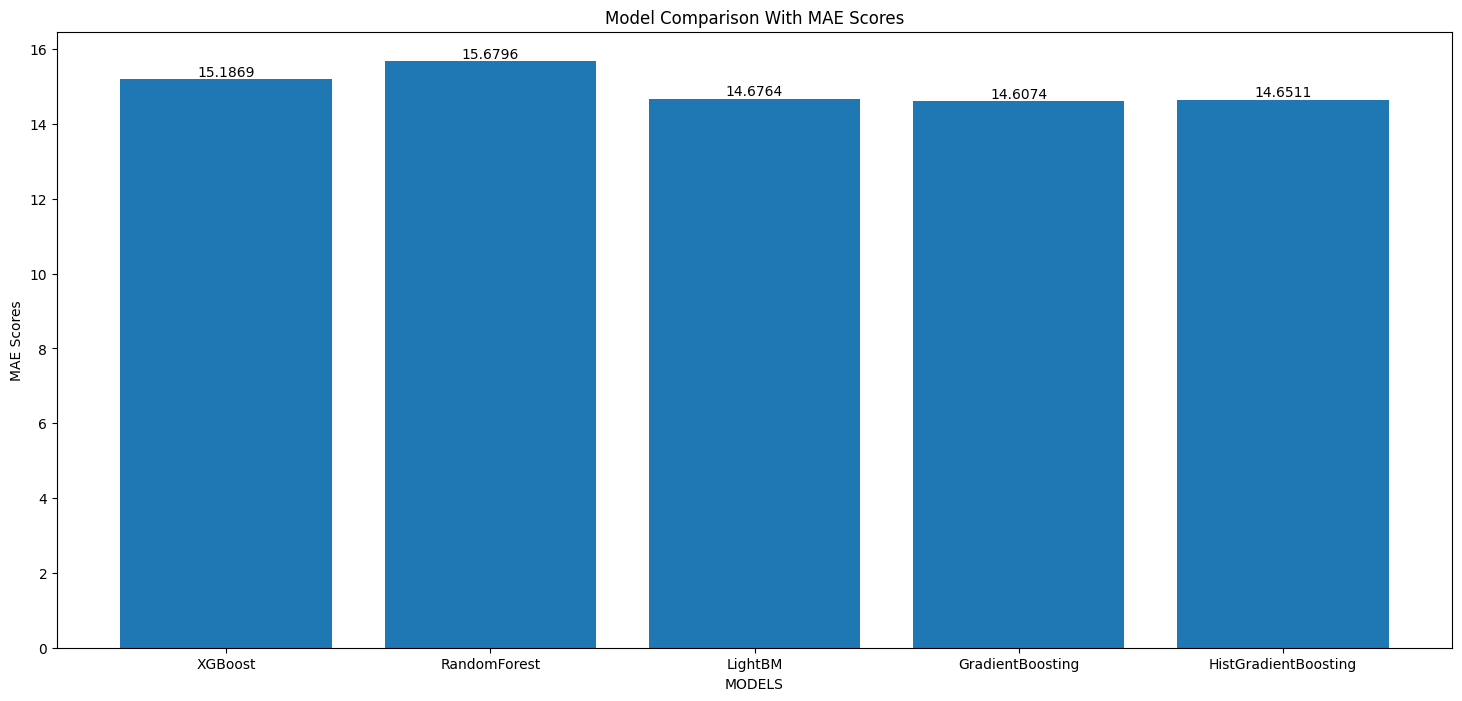

In [ ]:
mins = [min(xgb_mae_scores), min(rf_mae_scores), min(lgb_mae_scores), min(gbr_mae_scores),min(hgbr_mae_scores)]
labels = ['XGBoost', 'RandomForest', 'LightBM', 'GradientBoosting','HistGradientBoosting']

# Bar plot
plt.figure(figsize=(18,8))
bars =plt.bar(labels, mins)
plt.bar_label(bars, fmt="%.4f")
plt.title("Model Comparison With MAE Scores")
plt.xlabel("MODELS")
plt.ylabel("MAE Scores")
plt.show()

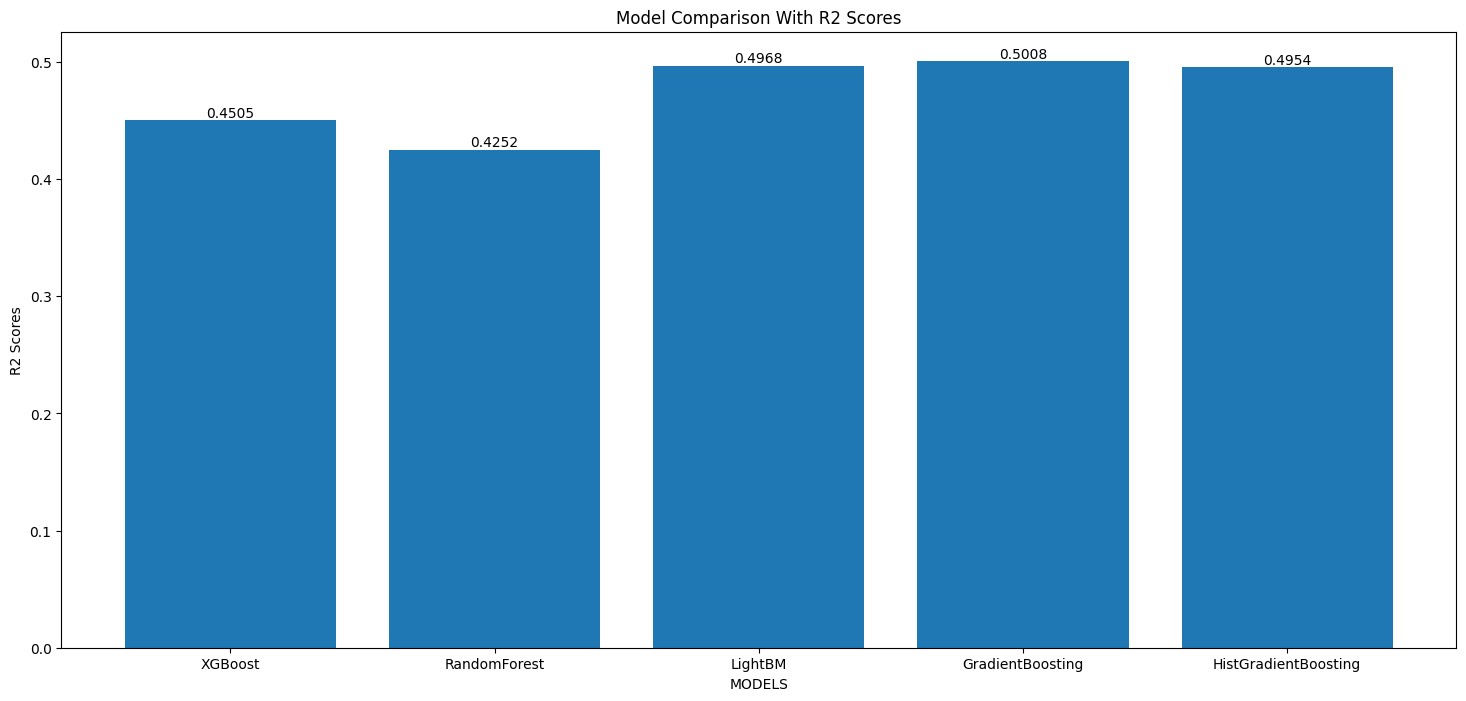

In [ ]:
maxs = [max(xgb_r2_scores), max(rf_r2_scores), max(lgb_r2_scores), max(gbr_r2_scores),max(hgbr_r2_scores)]
labels = ['XGBoost', 'RandomForest', 'LightBM', 'GradientBoosting','HistGradientBoosting']


# Bar plot
plt.figure(figsize=(18,8))
bars =plt.bar(labels, maxs)
plt.bar_label(bars, fmt="%.4f")
plt.title("Model Comparison With R2 Scores")
plt.xlabel("MODELS")
plt.ylabel("R2 Scores")
plt.show()

# Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

xgbr_params = {
    'n_estimators':[100,200,500],
    'learning_rate':[0.01,0.05,0.1],
    'max_depth':[3,5,7],
    'subsample':[0.7,1.0],
    'colsample_bytree':[0.7,1.0]
}
xgbr = XGBRegressor(random_state=42)

xgbr_rscv = RandomizedSearchCV(
    XGBRegressor(random_state=42),
    xgbr_params,
    cv=Time_Series_cv,
    n_iter=10,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

xgbr_rscv.fit(X, y)
'''preds = np.maximum(xgbr_rscv.predict(X_validate), 0)
xgbr_rscv_r2_score = r2_score(y_validate, preds)'''

print("Best Params:", xgbr_rscv.best_params_)
print("Best scores:", xgbr_rscv.best_score_)

Best Params: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.7}
Best scores: 0.4511144548060565


In [ ]:
'''rf_params = {
    'n_estimators': [50,100,200,300,500],
    'max_depth': [3,5,10,15, None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4]
}

rf_rscv = RandomForestRegressor(random_state=42)

rf_rscv = RandomizedSearchCV(
    rf_model,
    rf_params,
    n_iter=20,
    cv=Time_Series_cv,
    scoring='r2',
    random_state=42,
    n_jobs=1
)
rf_rscv.fit(X, y)

preds = np.maximum(gbr_rscv.predict(X_validate), 0)
gbr_rscv_r2_score=r2_score(y_validate, preds))

print("Best Params:", rf_rscv.best_params_)
print("Best scores:", rf_rscv.best_score_)
'''


'rf_params = {\n    \'n_estimators\': [50,100,200,300,500],\n    \'max_depth\': [3,5,10,15, None],\n    \'min_samples_split\': [2,5,10],\n    \'min_samples_leaf\': [1,2,4]\n}\n\nrf_rscv = RandomForestRegressor(random_state=42)\n\nrf_rscv = RandomizedSearchCV(\n    rf_model,\n    rf_params,\n    n_iter=20,\n    cv=Time_Series_cv,\n    scoring=\'r2\',\n    random_state=42,\n    n_jobs=1\n)\nrf_rscv.fit(X, y)\n\npreds = np.maximum(gbr_rscv.predict(X_validate), 0)\ngbr_rscv_r2_score=r2_score(y_validate, preds))\n\nprint("Best Params:", rf_rscv.best_params_)\nprint("Best scores:", rf_rscv.best_score_)\n'

In [ ]:
gbr_param = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [ 0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.5,  1.0],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8]
}
gbr = GradientBoostingRegressor(random_state=42)

gbr_rscv = RandomizedSearchCV(
    estimator=gbr,
    param_distributions=gbr_param,
    n_iter=30,
    cv=Time_Series_cv,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

gbr_rscv.fit(X, y)

'''preds = np.maximum(gbr_rscv.predict(X_validate), 0)
gbr_rscv_r2_score=r2_score(y_validate, preds))'''

print("Best Params:", gbr_rscv.best_params_)
print("Best scores:", gbr_rscv.best_score_)

Best Params: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 3, 'learning_rate': 0.05}
Best scores: 0.4542827159787219


# Best  Model

In [ ]:


# listing out best scores  of models
scores = {
    "XGBoost": xgbr_rscv.best_score_,
    #"RandomForest": rf_rscv.best_score_,
    "GradientBoosting": gbr_rscv.best_score_
}

print(scores)

# searching best model name with best score
best_model_name = max(scores, key=scores.get)
print("Best Model:", best_model_name)

# listing out best estimators  of models
best_model_dict = {
    "XGBoost": xgbr_rscv.best_estimator_,
    #"RandomForest": rf_rscv.best_estimator_,
    "GradientBoosting": gbr_rscv.best_estimator_
}

# selecting best model
best_model = best_model_dict[best_model_name]



{'XGBoost': 0.4511144548060565, 'GradientBoosting': 0.4542827159787219}
Best Model: GradientBoosting


In [ ]:
best_model.fit(X, y)
preds = np.maximum(best_model.predict(X_test), 0)

sample_submission = pd.DataFrame({
    "ID": test_forecast['book_theater_id'] + "_" + test_forecast['show_date'].dt.strftime('%Y-%m-%d'),
    "audience_count": preds
})
sample_submission = sample_submission.reset_index(drop=True)
sample_submission["audience_count"] = sample_submission["audience_count"].astype(int)
sample_submission.to_csv("submission.csv", index=False)
sample_submission.head()

,ID,audience_count
0,book_00001_2024-03-01,43
1,book_00001_2024-03-02,52
2,book_00001_2024-03-03,61
3,book_00001_2024-03-04,52
4,book_00001_2024-03-06,39
